In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  #A labrary built on top of matplotlib that provides a high-level interface for drawing attractive and informative statistical graphics.

sns.set_theme(style="whitegrid")


Matplotlib is building the font cache; this may take a moment.


In [3]:
train_df = pd.read_csv("../data/train.csv") 
test_df = pd.read_csv("../data/test.csv")   

In [4]:
print("Train data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

train_df.head()


Train data shape: (891, 12)
Test data shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Check data types and missing values
print("--- TRAIN DATA INFO ---")
print(train_df.info())

print("\n--- MISSING VALUES IN TRAIN SET ---")
print(train_df.isnull().sum())

--- TRAIN DATA INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None

--- MISSING VALUES IN TRAIN SET ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cab

C:\Users\aadmin\AppData\Local\Temp\ipykernel_14184\1207222789.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=train_df, ax=axes[0], palette='Set2')
C:\Users\aadmin\AppData\Local\Temp\ipykernel_14184\1207222789.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=train_df, ax=axes[1], palette='Set2')


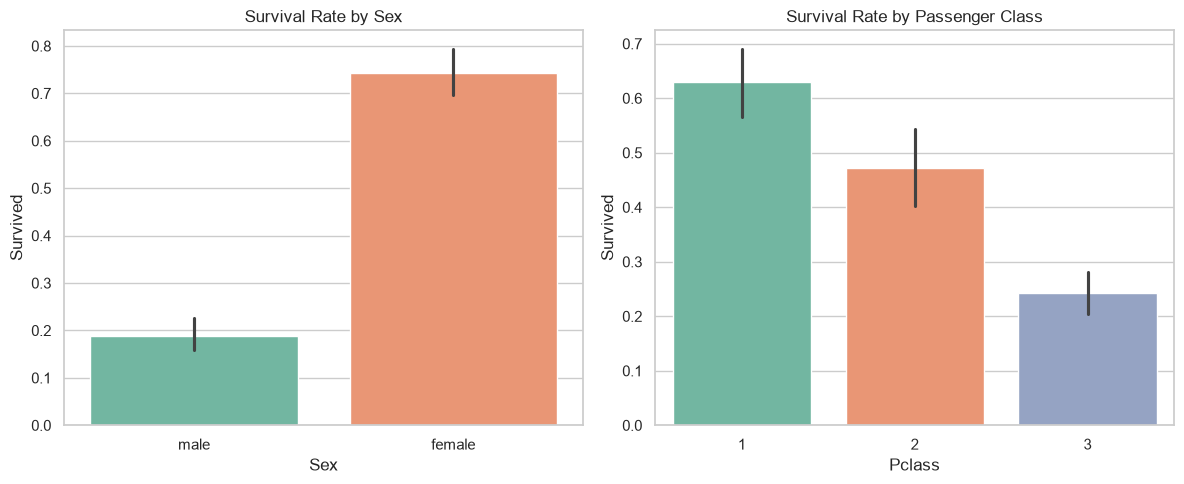

In [6]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Survival rate by Sex
sns.barplot(x='Sex', y='Survived', data=train_df, ax=axes[0], palette='Set2')
axes[0].set_title('Survival Rate by Sex')

# Plot 2: Survival rate by Pclass (Passenger Class)
sns.barplot(x='Pclass', y='Survived', data=train_df, ax=axes[1], palette='Set2')
axes[1].set_title('Survival Rate by Passenger Class')

plt.tight_layout()
plt.show()

In [7]:
# Create a copy of the training dataset to work on
df_clean = train_df.copy()

# 1. Fill missing Age values with the median age
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# 2. Fill missing Embarked values with the most frequent port (mode)
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# 3. Create 'Has_Cabin' feature (1 if they had a cabin recorded, 0 otherwise)
df_clean['Has_Cabin'] = df_clean['Cabin'].notna().astype(int)

# 4. Create 'FamilySize' feature (combining siblings/spouses and parents/children + self)
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1

# Verify that there are no more missing values in these columns
print("Missing values after cleaning:")
print(df_clean[['Age', 'Embarked', 'Has_Cabin', 'FamilySize']].isnull().sum())

Missing values after cleaning:
Age           0
Embarked      0
Has_Cabin     0
FamilySize    0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Select features and target variable
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Has_Cabin', 'FamilySize', 'Embarked']
X = df_clean[features].copy()
y = df_clean['Survived']

# 2. Convert text/categorical features into numbers (One-Hot Encoding)
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train Model 1: Logistic Regression (Baseline/Linear Model)
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
log_reg_acc = accuracy_score(y_val, log_reg.predict(X_val))

# 5. Train Model 2: Random Forest (Ensemble Model)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_acc = accuracy_score(y_val, rf_model.predict(X_val))

print(f"Logistic Regression Validation Accuracy: {log_reg_acc:.4f}")
print(f"Random Forest Validation Accuracy: {rf_acc:.4f}")

Logistic Regression Validation Accuracy: 0.8212
Random Forest Validation Accuracy: 0.8212


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       105
           1       0.79      0.77      0.78        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



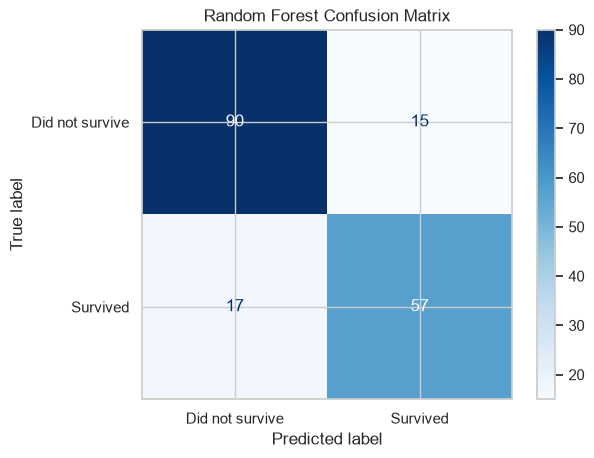

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Let's evaluate the Random Forest model
y_pred = rf_model.predict(X_val)

print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred))

# Plot the Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Did not survive', 'Survived'])

disp.plot(cmap=plt.cm.Blues)
plt.title('Random Forest Confusion Matrix')
plt.show()

C:\Users\aadmin\AppData\Local\Temp\ipykernel_14184\3579754680.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_names, palette='viridis')


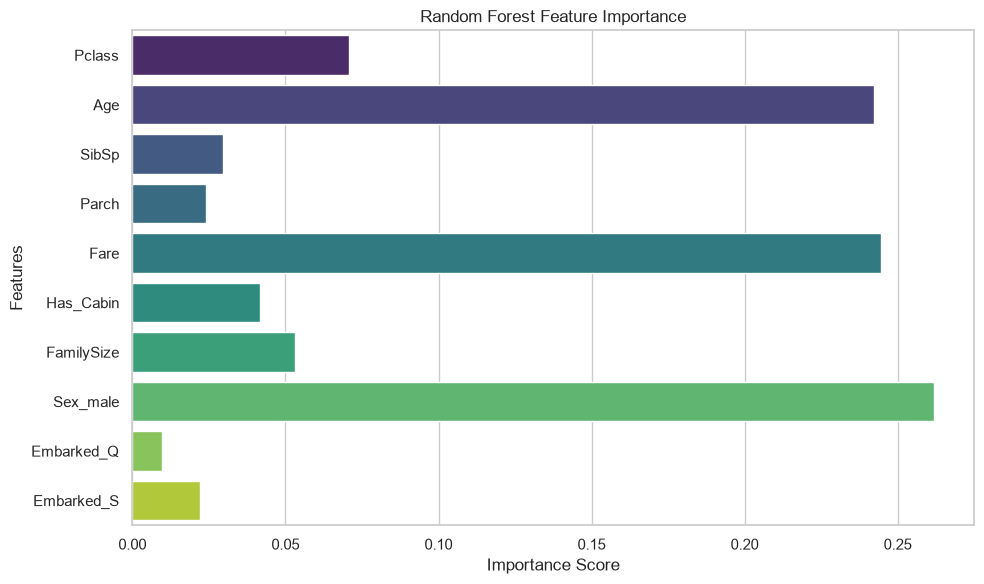

In [12]:
# 1. Plot and Save Feature Importances
importances = rf_model.feature_importances_
feature_names = X.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=importances, y=feature_names, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()

# Save plot to your images folder
plt.savefig('../images/feature_importance.png')
plt.show()

# 2. Save your confusion matrix plot as well
disp.plot(cmap=plt.cm.Blues)
plt.title('Random Forest Confusion Matrix')
plt.savefig('../images/confusion_matrix.png')
plt.close()